# Naive Bayes

One of the two baseline models from the paper (Section IV-A, originally from Kachavimath et al. [4]).

Gaussian Naive Bayes models each feature as a bell curve per class (normal vs DoS) and multiplies the per-feature probabilities together. That product assumes the features are **independent** given the class, which is the "naive" part. Training is just computing means and variances, so it is very fast. Defined in `src/dosdetect/models.py` as `naive_bayes()`.

In [1]:
import pandas as pd

from dosdetect.data import RESULTS_DIR, prepare_all
from dosdetect.evaluate import evaluate_all, metrics_table, paper_table, plot_confusions
from dosdetect.models import MODELS

pd.set_option("display.precision", 4)

## Data

Normal and DoS traffic only (`dosdetect.data.prepare_all`). Six setups, three splits at two feature counts:

- **official**: NSL-KDD, train on `KDDTrain+`, test on `KDDTest+`. A share of the test DoS rows are attack types never seen in training (apache2, mailbomb, processtable, udpstorm); the count is printed below.
- **holdout**: NSL-KDD, stratified 80/20 split of `KDDTrain+`, so every test attack type was also seen in training.
- **kddcup**: KDDCup'99 (10% file), stratified 80/20 split. The labelled KDDCup test file is no longer downloadable, so there is no official split for this dataset.
- **8 features** (top 8 by |Spearman correlation| with the label, our reading of the paper's filter) or **all 41**. On KDDCup this ranking reproduces the features the paper names (`dst_bytes`, `protocol_type`, the connection counts); on NSL-KDD it does not (see the README). The table below shows the NSL-KDD top 8.

In [2]:
data = prepare_all()
official = data[("official", 8)]
print("Train rows:", len(official["X_train"]), " Test rows:", len(official["X_test"]))
print(
    "Unseen DoS rows in official test:",
    official["unseen"].sum(),
    "of",
    int(official["y_test"].sum()),
    "DoS rows",
)
official["prep"].correlations.head(8).rename("|correlation| with label").to_frame()

Train rows: 113270  Test rows: 17169
Unseen DoS rows in official test: 1717 of 7458 DoS rows


,|correlation| with label
same_srv_rate,0.8433
flag,0.7974
diff_srv_rate,0.7747
serror_rate,0.7712
srv_serror_rate,0.7686
dst_host_serror_rate,0.7485
dst_host_srv_serror_rate,0.7410
count,0.7366


## Results

`recall_unseen` is the share of never-seen DoS attack types the model still catches (official split only).

In [3]:
results = evaluate_all(MODELS["naive_bayes"], data)
metrics_table(results)

,accuracy,precision,recall,f1,recall_seen,recall_unseen
"official, 8 features",0.8712,0.9293,0.7615,0.8371,0.8516,0.4601
"official, 41 features",0.6178,0.5395,0.8206,0.6510,0.9336,0.4426
"holdout, 8 features",0.9552,0.9577,0.9306,0.9440,NaN,NaN
"holdout, 41 features",0.6578,0.5434,0.9763,0.6982,NaN,NaN
"kddcup, 8 features",0.9872,0.9943,0.9896,0.9920,NaN,NaN
"kddcup, 41 features",0.9331,0.9281,0.9934,0.9597,NaN,NaN


### Compared with the paper

The paper reports one result per model, taken from [4] and measured across KDDCup **and** NSL-KDD ("across the two datasets"), with an unstated split and a different 8-feature set. We have no way to reproduce [4]'s split, so the table below takes our two 8-feature setups that are closest in spirit: NSL-KDD with the official train/test files and KDDCup with our 80/20 split. `mean` is the plain average of the two columns, the like-for-like counterpart of a single "across the two datasets" figure, and `difference` is `mean` minus the paper. The two columns differ a lot, so the mean hides most of the story: read the per-dataset columns first.

In [4]:
paper_table("naive_bayes", results)

,NSL-KDD,KDDCup,mean,paper [4],difference
accuracy,0.8712,0.9872,0.9292,0.9395,-0.0103
precision,0.9293,0.9943,0.9618,0.9774,-0.0156
recall,0.7615,0.9896,0.8755,0.9554,-0.0799


### Confusion matrices

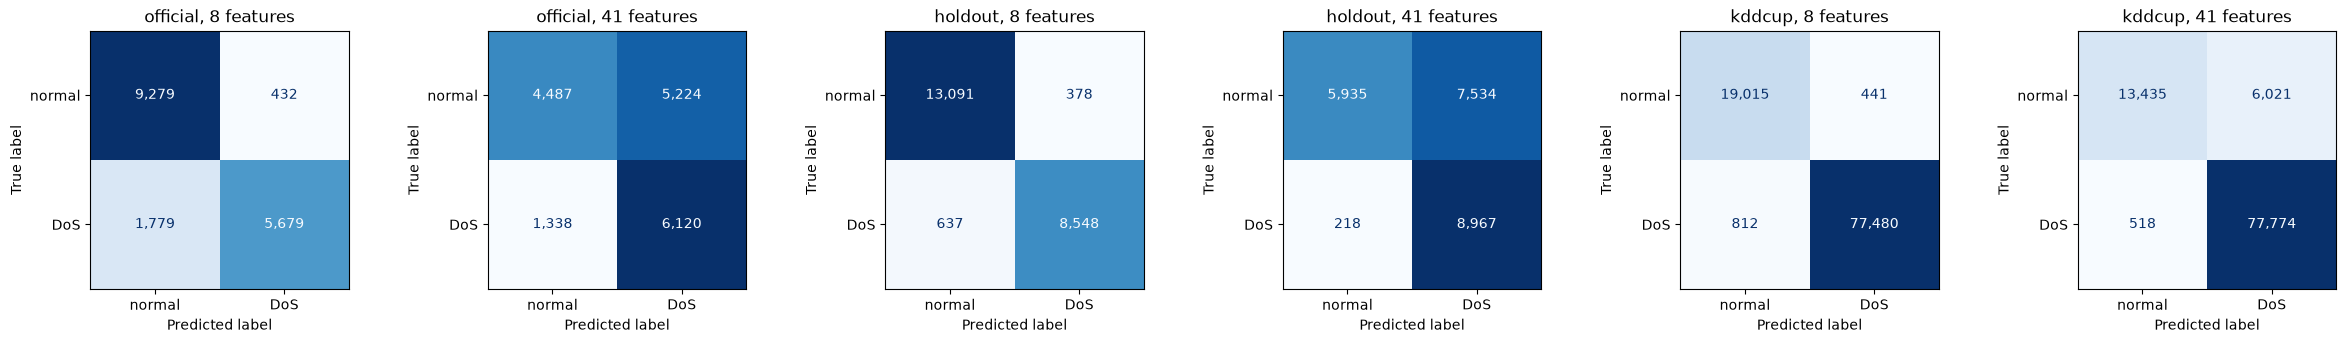

In [5]:
plot_confusions(results);

## Why more features can hurt Naive Bayes

Many NSL-KDD features are near-copies of each other (e.g. `serror_rate` and `srv_serror_rate`). Naive Bayes counts each copy as separate evidence, so duplicated features get over-weighted. The table counts feature pairs with |correlation| > 0.9 in the training data.

In [6]:
import numpy as np


def strongly_correlated_pairs(X, threshold=0.9):
    corr = X.corr().abs().to_numpy()
    return int(((corr > threshold) & np.triu(np.ones_like(corr, dtype=bool), k=1)).sum())


pd.DataFrame(
    {
        "pairs with |r| > 0.9": [
            strongly_correlated_pairs(data[("official", n)]["X_train"]) for n in (8, 41)
        ],
        "accuracy (official)": [results[("official", n)]["accuracy"] for n in (8, 41)],
        "precision (official)": [results[("official", n)]["precision"] for n in (8, 41)],
    },
    index=pd.Index([8, 41], name="features"),
)

,pairs with |r| > 0.9,accuracy (official),precision (official)
features,,,
8,6,0.8712,0.9293
41,14,0.6178,0.5395


## Timing

Median of 5 repeats per model (fresh model each time), read from `results/timing.csv`; nothing is re-timed here. The run was on an 8-core machine with other background load, and the forests use all cores, so absolute times depend on the machine; the ratios are within one setup. The second table is every model's predict time divided by Naive Bayes's in the same setup, so it shows what "cheapest" means; `train_ratio_vs_decision_tree` is Naive Bayes's train time divided by the decision tree's.

In [7]:
timing = pd.read_csv(RESULTS_DIR / "timing.csv")
print("repeats:", timing["repeats"].iloc[0], " cpu_count:", timing["cpu_count"].iloc[0])
nb_timing = timing[timing["model"] == "naive_bayes"].set_index(["split", "n_features"])
nb_timing[["train_s_median", "predict_s_median", "train_ratio_vs_decision_tree"]].round(4)

repeats: 5  cpu_count: 8


train_s_median  predict_s_median  \
split    n_features                                     
official 8                   0.0138            0.0012   
         41                  0.0371            0.0027   
holdout  8                   0.0092            0.0012   
         41                  0.0320            0.0033   
kddcup   8                   0.0404            0.0033   
         41                  0.1073            0.0138   

                     train_ratio_vs_decision_tree  
split    n_features                                
official 8                                 0.1619  
         41                                0.0869  
holdout  8                                 0.1939  
         41                                0.1036  
kddcup   8                                 0.2382  
         41                                0.1655

In [8]:
timing.pivot_table(
    index="model", columns=["split", "n_features"], values="predict_ratio_vs_naive_bayes"
).round(1)

split               holdout         kddcup         official       
n_features               8      41      8       41       8      41
model                                                             
decision_tree           1.4    0.6     0.8     0.4      1.4    0.6
knn                   817.6  413.9  4829.1  1770.5    725.9  503.8
naive_bayes             1.0    1.0     1.0     1.0      1.0    1.0
random_forest         151.7   48.7    66.7    15.9    142.5   58.2
random_forest_tuned   170.6   58.6    75.1    18.6    173.6   73.1

## Leave-one-attack-out

The official split has only a few unseen attack types, so it is one test of the claim that new attacks are missed. This section repeats it more broadly, from `results/attack_out.csv` (made by `python -m dosdetect.attack_out`, not re-run here). For each dataset (NSL-KDD `KDDTrain+` only, and KDDCup'99 10%) and each held-out group (neptune; smurf; back+land; teardrop+pod), the model is trained without any row of that group, on an 80% split of the rest, plus a fresh feature selection on that training set. It is tested on the other 20% plus the held-out rows (capped at 20,000). **One seed (42), so differences of a few points are within noise.**

- `recall_heldout`: share of the held-out attack rows flagged as DoS.
- `recall_seen`: recall on the DoS types it did train on.
- `false_alarm_rate`: share of normal test rows flagged as DoS.

In [9]:
attack_out = pd.read_csv(RESULTS_DIR / "attack_out.csv")
loao = attack_out[attack_out["model"] == "naive_bayes"].set_index(
    ["dataset", "n_features", "group"]
)
loao_cols = ["n_heldout", "recall_heldout", "recall_seen", "false_alarm_rate"]
loao[loao_cols]

n_heldout  recall_heldout  recall_seen  \
dataset n_features group                                                  
nsl-kdd 8          neptune           20000          0.3528       0.7635   
        41         neptune           20000          1.0000       1.0000   
        8          smurf              2646          1.0000       0.9784   
        41         smurf              2646          0.0382       0.9724   
        8          back+land           974          0.0195       1.0000   
        41         back+land           974          0.0185       0.9974   
        8          teardrop+pod       1093          0.0860       0.9558   
        41         teardrop+pod       1093          0.8902       0.9774   
kddcup  8          neptune           20000          0.2165       0.9874   
        41         neptune           20000          0.0000       0.9874   
        8          smurf             20000          0.9999       0.9738   
        41         smurf             20000          0.0000       0.9741   
        8          back+land          2224          0.0004       0.9986   
        41         back+land          2224          0.0000       0.9988   
        8          teardrop+pod       1243          0.5366       0.9920   
        41         teardrop+pod       1243          0.7434       0.9940   

                                 false_alarm_rate  
dataset n_features group                           
nsl-kdd 8          neptune                 0.0530  
        41         neptune                 0.9099  
        8          smurf                   0.9892  
        41         smurf                   0.2214  
        8          back+land               0.1668  
        41         back+land               0.1540  
        8          teardrop+pod            0.0258  
        41         teardrop+pod            0.5392  
kddcup  8          neptune                 0.0044  
        41         neptune                 0.0057  
        8          smurf                   0.0698  
        41         smurf                   0.0393  
        8          back+land               0.0396  
        41         back+land               0.0382  
        8          teardrop+pod            0.0261  
        41         teardrop+pod            0.3111

Mean over the four groups for each dataset and feature count (a mean can hide a single group doing very differently; read the per-group table above first):

In [10]:
loao_mean = loao.groupby(level=["dataset", "n_features"])[
    ["recall_heldout", "recall_seen", "false_alarm_rate"]
].mean()
loao_mean.round(4)

recall_heldout  recall_seen  false_alarm_rate
dataset n_features                                               
kddcup  8                   0.4384       0.9880            0.0350
        41                  0.1858       0.9886            0.0986
nsl-kdd 8                   0.3646       0.9244            0.3087
        41                  0.4867       0.9868            0.4561

In [11]:
flagged = loao[loao["recall_heldout"] > 0.5]
print("rows with recall_heldout > 0.5:", len(flagged), "of", len(loao))
print("of those, false_alarm_rate > 0.25:", int((flagged["false_alarm_rate"] > 0.25).sum()))
print("rows with recall_heldout < 0.1:", int((loao["recall_heldout"] < 0.1).sum()), "of", len(loao))
flagged[loao_cols].sort_values("false_alarm_rate", ascending=False)

rows with recall_heldout > 0.5: 6 of 16
of those, false_alarm_rate > 0.25: 4
rows with recall_heldout < 0.1: 8 of 16


n_heldout  recall_heldout  recall_seen  \
dataset n_features group                                                  
nsl-kdd 8          smurf              2646          1.0000       0.9784   
        41         neptune           20000          1.0000       1.0000   
                   teardrop+pod       1093          0.8902       0.9774   
kddcup  41         teardrop+pod       1243          0.7434       0.9940   
        8          smurf             20000          0.9999       0.9738   
                   teardrop+pod       1243          0.5366       0.9920   

                                 false_alarm_rate  
dataset n_features group                           
nsl-kdd 8          smurf                   0.9892  
        41         neptune                 0.9099  
                   teardrop+pod            0.5392  
kddcup  41         teardrop+pod            0.3111  
        8          smurf                   0.0698  
                   teardrop+pod            0.0261

## Takeaways

- **Closest to the paper of the models here, but still short on recall.** The two-dataset mean with 8 features is 92.9% accuracy against the paper's 93.95% (1.0 points low), and 87.6% recall against 95.5% (8.0 points low), per the comparison table. Per dataset, KDDCup gives 98.7% accuracy and 99.0% recall, while the official NSL-KDD file gives 87.1% and 76.2%.
- **Unseen attacks are caught more often than by the other models.** Recall on never-seen DoS types is 46.0% with 8 features and 44.3% with 41, versus 85.2% on seen types at 8 features. Its rough bell-curve picture of each class generalises further than a tight fit to the training data (see the KNN and decision tree notebooks for their unseen recall). This is recall alone, though; the leave-one-attack-out section below shows what it costs in false alarms.
- **Breaks down with all 41 features.** On the official split accuracy falls from 87.1% to 61.8% and precision from 92.9% to 54.0%, so nearly half of its DoS alarms are normal traffic. The 41-feature set has 14 near-duplicate feature pairs against 6 for the 8-feature set, and the independence assumption counts each copy as extra evidence. The same direction shows on holdout (95.5% to 65.8%) and kddcup (98.7% to 93.3%) accuracy. Correlation-based feature selection matters most for this model.
- **Cheapest model.** In the timing table Naive Bayes trains in 0.0092 s to 0.1073 s (median of 5 runs) and predicts in 0.0012 s to 0.0138 s across the six setups. Its train time is 0.0869 to 0.2382 of the decision tree's (`train_ratio_vs_decision_tree`), and its predict time is within a factor of about 1.7 of the tree's either way (ratios 0.4 to 1.4 in the second table). KNN's predict time is 414x to 4829x Naive Bayes's. Medians on an 8-core machine with other background load.
- **Leave-one-attack-out contradicts the idea that Naive Bayes generalises better to new attacks.** (One seed.) Its group-mean `recall_heldout` looks high (for example 0.4867 on nsl-kdd with 41 features, with a mean false-alarm rate of 0.4561), but the per-group table shows why that is misleading. The recall is all-or-nothing: 6 of 16 rows exceed 0.5 and 8 of 16 are below 0.1, and the same group flips between feature counts (nsl-kdd smurf: 1.0000 at 8 features, 0.0382 at 41). Where recall is high it is often bought by flagging normal traffic: of the 6 high-recall rows, 4 have a false-alarm rate above 0.25, with nsl-kdd smurf at 8 features flagging 98.92% of normal rows. The two cleaner cases are on KDDCup (smurf at 8 features: recall 0.9999 with false alarms 0.0698; teardrop+pod at 8 features: 0.5366 with 0.0261). The KNN and decision tree notebooks show models that miss unseen groups but keep false alarms near zero. So the official-split result (46.0% unseen recall) is not a reliable sign of generalisation: Naive Bayes is closer to guessing DoS on a shifted distribution than to recognising new attacks.
